# 07 · Real quantum hardware check

All experiments so far used a simulator: exact similarities, and in `05_shot_noise` simulated shot noise. Real hardware adds its own errors (imperfect gates, decoherence, readout errors). This notebook measures a sample of kernel similarities of **every dataset** on an IBM quantum computer and compares them with the exact values.

**Circuit.** The similarity of rows x and x′ is measured with the compute–uncompute circuit: encode x, then apply the inverse encoding of x′, then measure every qubit. The share of all-zero outcomes estimates |⟨φ(x′)|φ(x)⟩|² = K(x, x′). A barrier between the two halves stops the compiler from cancelling them.

**Design (per dataset).** 8 training rows (4 per class) → 28 pairs, plus 4 rows compared with themselves (exact similarity 1, so any loss is pure hardware error). 4,000 shots per circuit, all jobs on `ibm_fez`.

| Dataset | Qubits | Bandwidths measured |
|---|---|---|
| Phoneme | 5 | 0.01, 0.1, 1.0 |
| German Credit | 14 | 0.01, 0.1 |
| Electricity, Concrete, MAGIC, Water, Steel, Bank | 6–14 | 0.1 |

The first plan measured all three bandwidths for every dataset. After the Phoneme jobs, the measured cost (about 0.018 of the 10 free resource units per circuit) showed that this would exceed the free quantum time, so before any other dataset was measured the design was reduced to the table above: c = 0.1 for every dataset (the bandwidth most often chosen in the experiments), plus the small bandwidth on Phoneme (fewest qubits) and German Credit (14 qubits, best c = 0.01).

| Job | Datasets | Circuits | Date |
|---|---|---|---|
| 1 | Phoneme, c = 0.1 (`job.json`) | 32 | 5 Nov 2026 |
| 2 | Phoneme, c = 0.01 and 1.0 | 64 | 5 Nov 2026 |
| 3–6 | Electricity, Concrete, MAGIC, Water | 4 × 32 | 7 Nov 2026 |
| 7–9 | German (64), Steel, Bank (32 each) | 128 | 7 Nov 2026 |

**Questions.**
1. How much does real hardware change the similarities, and does the damage grow with the number of qubits (5 to 14)?
2. Does hardware keep the **order** of the similarities (which pair is more similar), at each bandwidth? The SVM needs that order.
3. How does the real error compare with the shot-noise model used in `05_shot_noise`?

**Safety.** Sections 1–3 run on the laptop only. Real jobs are sent only when `RUN_ON_HARDWARE = True`, and only for the datasets listed in `SEND_NOW`. Each job ID is saved at once in `results/ibm/`; a dataset that already has a job is never sent again; results can always be downloaded again (section 5). The Phoneme job at c = 0.1 from the first run is reused.

## 0 · Setup

Two settings controlled the real jobs; all jobs are finished, so keep `RUN_ON_HARDWARE = False`:

- `RUN_ON_HARDWARE` — the master switch, `True` only while sending.
- `SEND_NOW` — the datasets sent in that run.

Running the whole notebook with the switch off uses no quantum time: section 5 reads the saved counts in `results/ibm/` and section 6 rebuilds every table and figure.

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.stats import spearmanr

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit_ibm_runtime.fake_provider import FakeFez

from paths import RESULTS
from quantum_kernel import load_ready, get_states, kernel_from_states

warnings.filterwarnings("ignore", category=DeprecationWarning)

RUN_ON_HARDWARE = False
SEND_NOW = ["german_credit", "steel_faults", "bank_marketing"]

DATASETS = ["phoneme", "electricity", "concrete", "magic_telescope", "water_potability",
            "german_credit", "steel_faults", "bank_marketing"]          # fewest qubits first
SHORT = {"german_credit": "German", "concrete": "Concrete", "water_potability": "Water", "steel_faults": "Steel",
         "phoneme": "Phoneme", "magic_telescope": "MAGIC", "bank_marketing": "Bank", "electricity": "Electricity"}
C_LIST, N_ROWS, SHOTS, BACKEND = [0.01, 0.1, 1.0], 8, 4000, "ibm_fez"
OUT = RESULTS / "ibm"
OUT.mkdir(parents=True, exist_ok=True)

pairs = list(combinations(range(N_ROWS), 2)) + [(i, i) for i in range(4)]
SELF = np.arange(len(pairs)) >= len(pairs) - 4
data = {}
for name in DATASETS:
    X, y, _, _ = load_ready(name)
    rng = np.random.default_rng(0)
    rows = np.sort(np.concatenate([rng.choice(np.where(y == k)[0], N_ROWS // 2, replace=False) for k in (0, 1)]))
    data[name] = {"X": X[rows], "rows": rows, "q": X.shape[1]}
pd.DataFrame({SHORT[n]: {"qubits": d["q"], "rows": d["rows"].tolist()} for n, d in data.items()}).T

,qubits,rows
Phoneme,5,"[1, 43, 82, 152, 161, 186, 201, 238]"
Electricity,6,"[1, 40, 72, 148, 171, 191, 210, 238]"
Concrete,8,"[2, 38, 81, 154, 168, 193, 219, 236]"
MAGIC,8,"[2, 32, 80, 148, 166, 188, 211, 237]"
Water,9,"[1, 46, 77, 151, 166, 191, 209, 236]"
German,14,"[3, 46, 76, 143, 170, 181, 224, 233]"
Steel,14,"[2, 32, 80, 149, 164, 189, 212, 237]"
Bank,14,"[0, 15, 84, 137, 148, 179, 183, 238]"


## 1 · The circuits

The same feature map as `quantum_kernel.py`: two repetitions of (Hadamard and RZ(2x) on every qubit, then CNOT – RZ(2(π − xᵢ)(π − xᵢ₊₁)) – CNOT between neighbours), every feature multiplied by c.

The Phoneme job at c = 0.1 already exists from the first run (`job.json`, `counts.csv`), so it is not measured again.

`PLAN` and `c_to_send` hold the final design from the table above.

In [2]:
def feature_map(x, c, reps=2):
    x = c * np.asarray(x)
    qc = QuantumCircuit(len(x))
    for _ in range(reps):
        for i in range(len(x)):
            qc.h(i)
            qc.rz(2 * x[i], i)
        for i in range(len(x) - 1):
            qc.cx(i, i + 1)
            qc.rz(2 * (np.pi - x[i]) * (np.pi - x[i + 1]), i + 1)
            qc.cx(i, i + 1)
    return qc


def kernel_circuit(X, a, b, c):
    qc = feature_map(X[a], c)
    qc.barrier()
    qc = qc.compose(feature_map(X[b], c).inverse())
    qc.measure_all()
    return qc


OLD_COUNTS = OUT / "counts.csv"          # first run: Phoneme, c = 0.1


PLAN = {"phoneme": [0.01, 1.0], "german_credit": [0.01, 0.1]}   # others: c = 0.1 only (quantum-time budget)


def c_to_send(name):
    return PLAN.get(name, [0.1])


jobs = {}
for name, d in data.items():
    jobs[name] = [(c, a, b) for c in c_to_send(name) for a, b in pairs]
    d["circuits"] = [kernel_circuit(d["X"], a, b, c) for c, a, b in jobs[name]]
print(f"{sum(len(d['circuits']) for d in data.values())} circuits in total to send "
      f"({len(pairs)} per dataset and bandwidth; Phoneme c = 0.1 reused)")

320 circuits in total to send (32 per dataset and bandwidth; Phoneme c = 0.1 reused)


## 2 · Check: the circuits give exactly our kernel

Without measurement, the probability of the all-zero outcome must equal the kernel from `quantum_kernel.py` for every pair, dataset and bandwidth.

In [19]:
zero_of = lambda q: "0" * q
exact, rows_check = {}, {}
for name, d in data.items():
    for c in C_LIST:
        S = get_states(d["X"], d["q"], c=c)
        K = kernel_from_states(S, S)
        exact[name, c] = np.array([K[a, b] for a, b in pairs])
    p0 = np.array([Statevector(qc.remove_final_measurements(inplace=False).decompose()).probabilities_dict().get(zero_of(d["q"]), 0.0)
                   for qc in d["circuits"]])
    ref = np.concatenate([exact[name, c] for c in c_to_send(name)])
    rows_check[SHORT[name]] = {"largest difference": f"{np.abs(p0 - ref).max():.1e}",
                               **{f"spread of pairs, c = {c}": round(exact[name, c][~SELF].std(), 4) for c in C_LIST}}
    assert np.abs(p0 - ref).max() < 1e-10, f"{name}: circuits do not match quantum_kernel.py - stop"
pd.DataFrame(rows_check).T

,largest difference,"spread of pairs, c = 0.01","spread of pairs, c = 0.1","spread of pairs, c = 1.0"
Phoneme,4.4e-15,0.0044,0.2121,0.065
Electricity,3.7e-15,0.0099,0.224,0.0301
Concrete,5.3e-15,0.0103,0.2242,0.0758
MAGIC,4.9e-15,0.0064,0.215,0.0111
Water,6.3e-15,0.0059,0.1969,0.0007
German,1.4e-14,0.0437,0.0502,0.0123
Steel,6.1e-15,0.0455,0.1794,0.001
Bank,4.5e-15,0.022,0.0751,0.0028


## 3 · Rehearsal on a simulated IBM processor (no quantum time)

`FakeFez` copies the layout and measured error rates of `ibm_fez`. For every dataset a sample (the 4 self-pairs and 4 pairs at c = 0.1) is compiled exactly as it will be sent, which shows the circuit size. The sample is also run with simulated hardware noise for the datasets with up to 9 qubits; simulating noisy 14-qubit circuits on a laptop takes too long, so those are only compiled.

In [20]:
fake = FakeFez()
pm_fake = generate_preset_pass_manager(optimization_level=3, backend=fake)
sizes = {}
for name, d in data.items():
    t = time.perf_counter()
    isa = pm_fake.run([kernel_circuit(d["X"], a, b, 0.1) for a, b in pairs[:4] + pairs[-4:]])
    row = {"qubits": d["q"], "circuits to send": len(d["circuits"]),
           "two-qubit gates": max(sum(v for k, v in qc.count_ops().items() if k in ("cz", "ecr", "cx")) for qc in isa)}
    if d["q"] <= 9:
        res = SamplerV2(mode=fake).run(isa, shots=1000).result()
        vals = np.array([r.data.meas.get_counts().get(zero_of(d["q"]), 0) / 1000 for r in res])
        row["simulated self-pairs (exact 1)"] = round(vals[4:].mean(), 3)
    row["seconds"] = round(time.perf_counter() - t)
    sizes[SHORT[name]] = row
pd.DataFrame(sizes).T.fillna("-")

,qubits,circuits to send,two-qubit gates,simulated self-pairs (exact 1),seconds
Phoneme,5.0,64.0,32.0,0.89,14.0
Electricity,6.0,32.0,40.0,0.868,15.0
Concrete,8.0,32.0,56.0,0.816,15.0
MAGIC,8.0,32.0,56.0,0.796,15.0
Water,9.0,32.0,64.0,0.78,45.0
German,14.0,64.0,104.0,-,0.0
Steel,14.0,32.0,104.0,-,0.0
Bank,14.0,32.0,104.0,-,0.0


## 4 · Send the real jobs (uses quantum time)

Only when `RUN_ON_HARDWARE = True`, and only for the datasets in `SEND_NOW`. Each job ID is saved to `results/ibm/job_<dataset>.json` before waiting; a dataset that already has a job file is skipped.

In [21]:
if not RUN_ON_HARDWARE:
    print("RUN_ON_HARDWARE = False: nothing sent to IBM.")
else:
    service = QiskitRuntimeService()
    backend = service.backend(BACKEND)
    for name in SEND_NOW:
        job_file = OUT / f"job_{name}.json"
        if job_file.exists():
            print(f"{SHORT[name]}: job already submitted - skipped"); continue
        isa = generate_preset_pass_manager(optimization_level=3, backend=backend).run(data[name]["circuits"])
        job = SamplerV2(mode=backend).run(isa, shots=SHOTS)
        job_file.write_text(json.dumps({"job_id": job.job_id(), "backend": backend.name, "dataset": name,
                                        "rows": data[name]["rows"].tolist(), "circuits": jobs[name], "shots": SHOTS,
                                        "submitted": time.strftime("%Y-%m-%d %H:%M:%S")}, indent=2))
        print(f"{SHORT[name]}: submitted job {job.job_id()} ({len(isa)} circuits) to {backend.name}")

German: submitted job dbng4a0ou4as73b4i0ng (64 circuits) to ibm_fez
Steel: submitted job dbng4b0ou4as73b4i0pg (32 circuits) to ibm_fez
Bank: submitted job dbng4bgqtr0c73ad1uj0 (32 circuits) to ibm_fez


## 5 · Download the results

Reads every saved job ID; downloads finished jobs to `results/ibm/counts_<dataset>.csv` and reports the quantum time each job used. Run it again later for jobs that are still queued. No quantum time is used.

In [22]:
measured, status, service = {}, {}, None
if OLD_COUNTS.exists():
    measured["phoneme", 0.1] = pd.read_csv(OLD_COUNTS).pipe(lambda g: g.zeros.values / g.shots.values)
for name, d in data.items():
    job_file, counts_file = OUT / f"job_{name}.json", OUT / f"counts_{name}.csv"
    if not counts_file.exists() and job_file.exists():
        service = service or QiskitRuntimeService()
        info = json.loads(job_file.read_text())
        job = service.job(info["job_id"])
        st = str(job.status())
        if st == "DONE":
            res = job.result()
            pd.DataFrame([{"c": c, "a": a, "b": b, "zeros": r.data.meas.get_counts().get(zero_of(d["q"]), 0), "shots": SHOTS}
                          for (c, a, b), r in zip(jobs[name], res)]).to_csv(counts_file, index=False)
            try:
                info["quantum_seconds"] = job.usage()
                job_file.write_text(json.dumps(info, indent=2))
            except Exception:
                pass
        status[SHORT[name]] = {"status": st}
    if counts_file.exists():
        g = pd.read_csv(counts_file)
        for c in g.c.unique():
            measured[name, c] = g[g.c == c].pipe(lambda h: h.zeros.values / h.shots.values)
        info = json.loads(job_file.read_text()) if job_file.exists() else {}
        status[SHORT[name]] = {"status": "downloaded", "quantum seconds": info.get("quantum_seconds", "")}
    status.setdefault(SHORT[name], {"status": "not sent"})
pd.DataFrame(status).T

,status,quantum seconds
Phoneme,downloaded,69
Electricity,downloaded,36
Concrete,downloaded,36
MAGIC,downloaded,36
Water,downloaded,36
German,downloaded,70
Steel,downloaded,36
Bank,downloaded,36


## 6 · Exact vs hardware

All jobs together (every batch), one row per dataset and bandwidth:

- **self-pairs**: exact 1; the measured value is the share that survives hardware error;
- **slope**: measured ≈ slope × exact + offset; a slope below 1 means hardware shrinks all similarities;
- **rank agreement** (Spearman): does hardware keep the order of the 28 similarities? 1 = same order;
- **signal / error**: the spread of the exact similarities divided by the hardware error left after rescaling; below about 1, hardware noise is as large as the differences the SVM needs;
- **inside shot band**: share of pairs within the 95 % band of the shot-noise model of `05_shot_noise`.

In [23]:
def compare(e, m):
    a, b = np.polyfit(e[~SELF], m[~SELF], 1)
    resid = m[~SELF] - (a * e[~SELF] + b)
    band = 1.96 * np.sqrt(np.clip(e * (1 - e), 0, None) / SHOTS)
    return {"self-pairs": m[SELF].mean(), "slope": a,
            "rank agreement": spearmanr(e[~SELF], m[~SELF])[0],
            "signal / error": e[~SELF].std() / resid.std(),
            "inside shot band": (np.abs(m - e)[~SELF] <= band[~SELF]).mean()}


rows = []
for name, d in data.items():
    for c in C_LIST:
        if (name, c) in measured:
            rows.append({"dataset": SHORT[name], "qubits": d["q"], "c": c, **compare(exact[name, c], measured[name, c])})
HW = pd.DataFrame(rows)
if HW.empty:
    print("No hardware results yet.")
else:
    HW.to_csv(RESULTS / "analysis" / "ibm_hardware_all.csv", index=False)
    display(HW.set_index(["dataset", "qubits", "c"]).round(3))

self-pairs  slope  rank agreement  signal / error  \
dataset     qubits c                                                         
Phoneme     5      0.01       0.794  1.236           0.566           0.587   
                   0.10       0.664  0.663           0.986           9.898   
                   1.00       0.764  0.737           0.976           6.877   
Electricity 6      0.10       0.754  0.812           0.985           6.051   
Concrete    8      0.10       0.703  0.720           0.986          18.477   
MAGIC       8      0.10       0.677  0.645           0.963           8.384   
Water       9      0.10       0.582  0.575           0.984          16.517   
German      14     0.01       0.346  0.211           0.453           2.743   
                   0.10       0.388  0.353           0.946           7.246   
Steel       14     0.10       0.371  0.298           0.951          26.676   
Bank        14     0.10       0.318  0.288           0.879           8.721   

                         inside shot band  
dataset     qubits c                       
Phoneme     5      0.01             0.000  
                   0.10             0.000  
                   1.00             0.286  
Electricity 6      0.10             0.036  
Concrete    8      0.10             0.143  
MAGIC       8      0.10             0.000  
Water       9      0.10             0.000  
German      14     0.01             0.000  
                   0.10             0.536  
Steel       14     0.10             0.464  
Bank        14     0.10             0.250

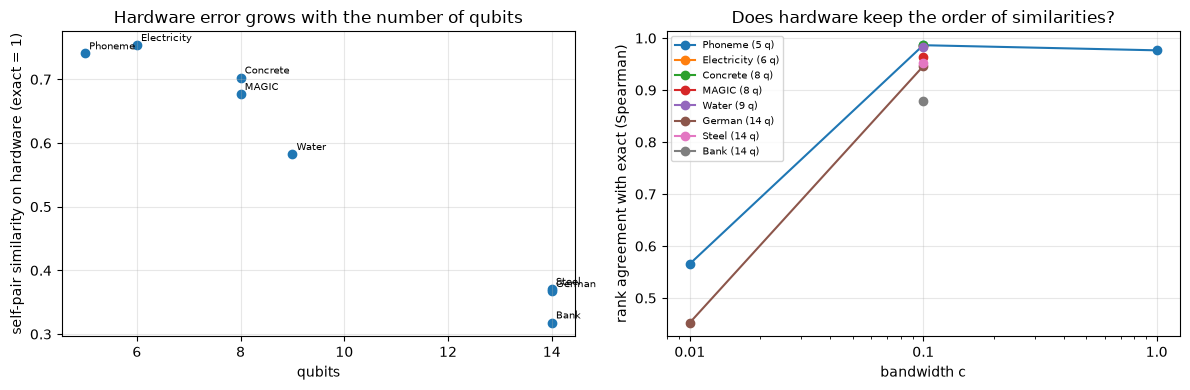

In [24]:
if not HW.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sp = HW.drop_duplicates(["dataset"]).sort_values("qubits")
    selfp = HW.groupby(["dataset", "qubits"])["self-pairs"].mean().reset_index().sort_values("qubits")
    axes[0].scatter(selfp.qubits, selfp["self-pairs"])
    for _, r in selfp.iterrows():
        axes[0].annotate(r.dataset, (r.qubits, r["self-pairs"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    axes[0].set_xlabel("qubits"); axes[0].set_ylabel("self-pair similarity on hardware (exact = 1)")
    axes[0].set_title("Hardware error grows with the number of qubits"); axes[0].grid(alpha=0.3)
    for name in HW.dataset.unique():
        g = HW[HW.dataset == name].sort_values("c")
        axes[1].plot(g.c, g["rank agreement"], "o-", label=f"{name} ({g.qubits.iloc[0]} q)")
    axes[1].set_xscale("log"); axes[1].set_xticks(C_LIST); axes[1].set_xticklabels([str(c) for c in C_LIST])
    axes[1].set_xlabel("bandwidth c"); axes[1].set_ylabel("rank agreement with exact (Spearman)")
    axes[1].set_title("Does hardware keep the order of similarities?"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(RESULTS / "analysis" / "fig_ibm_hardware_all.png", dpi=150); plt.show()

In [25]:
%pip install pylatexenc

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 7 · Circuit figures for the paper

(a) How one similarity is measured: encode x, barrier, inverse encoding of x′, measure every qubit; the share of all-zero outcomes estimates K(x, x′). (b) One repetition of the feature map U_φ(x) for 5 qubits (two repetitions are used): RZ(2c·xᵢ) on every qubit, and φᵢⱼ = 2(π − c·xᵢ)(π − c·xⱼ) between neighbouring qubits. Both are saved to `results/analysis/`. No quantum time is used.

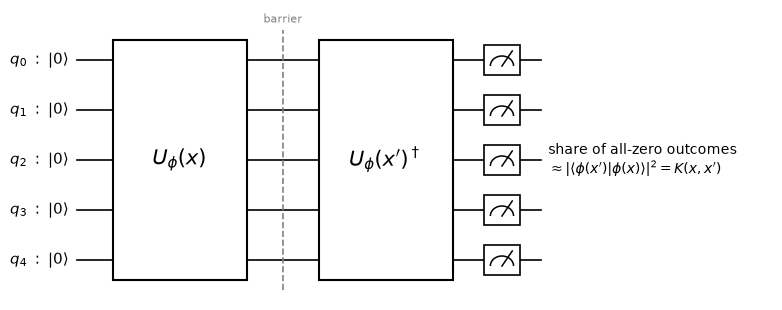

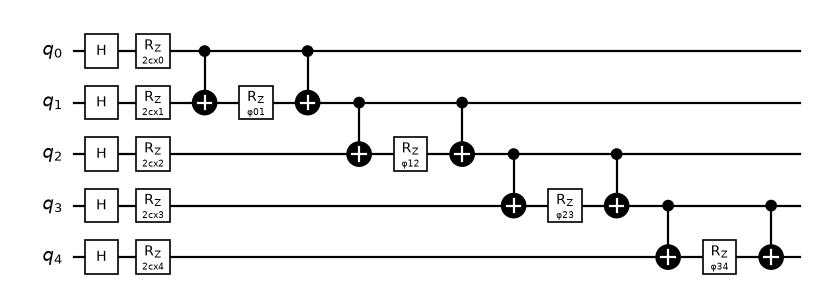

Saved fig_circuit_scheme.png and fig_circuit_feature_map.png in results/analysis/


In [3]:
from qiskit.circuit import Parameter
from matplotlib.patches import Rectangle, Arc

N_SHOW = 5                                   # Phoneme: 5 qubits

# (a) the measurement scheme: encode x, barrier, undo the encoding of x', measure all qubits
fig_a, ax = plt.subplots(figsize=(8, 3.2))
ys = np.arange(N_SHOW)[::-1]
for i, y_ in enumerate(ys):
    ax.plot([0.3, 9.3], [y_, y_], color="black", lw=1.2)
    ax.text(0.15, y_, "$q_" + str(i) + r"\ :\ |0\rangle$", ha="right", va="center", fontsize=11)
for x0, label in [(1.0, r"$U_\phi(x)$"), (5.0, r"$U_\phi(x')^\dagger$")]:
    ax.add_patch(Rectangle((x0, -0.4), 2.6, N_SHOW - 0.2, facecolor="white", edgecolor="black", lw=1.5, zorder=3))
    ax.text(x0 + 1.3, (N_SHOW - 1) / 2, label, ha="center", va="center", fontsize=15, zorder=4)
ax.plot([4.3, 4.3], [-0.6, N_SHOW - 0.4], ls="--", color="grey", lw=1.2)
ax.text(4.3, N_SHOW - 0.25, "barrier", ha="center", fontsize=8, color="grey")
for y_ in ys:
    ax.add_patch(Rectangle((8.2, y_ - 0.3), 0.7, 0.6, facecolor="white", edgecolor="black", lw=1.2, zorder=3))
    ax.add_patch(Arc((8.55, y_ - 0.12), 0.45, 0.4, theta1=0, theta2=180, lw=1.1, zorder=4))
    ax.plot([8.55, 8.75], [y_ - 0.12, y_ + 0.18], color="black", lw=1.1, zorder=4)
ax.text(9.45, (N_SHOW - 1) / 2, "share of all-zero outcomes\n" + r"$\approx |\langle\phi(x')|\phi(x)\rangle|^2 = K(x, x')$",
        va="center", fontsize=10)
ax.set_xlim(-0.6, 13.8); ax.set_ylim(-0.8, N_SHOW); ax.axis("off")
plt.tight_layout()
fig_a.savefig(RESULTS / "analysis" / "fig_circuit_scheme.png", dpi=300, bbox_inches="tight")
plt.show()

# (b) one repetition of the feature map U_phi(x) (two repetitions are used), with symbolic angles:
#     2c·x_i on every qubit, and phi_ij = 2(pi - c·x_i)(pi - c·x_j) between neighbours
one_rep = QuantumCircuit(N_SHOW)
for i in range(N_SHOW):
    one_rep.h(i)
    one_rep.rz(Parameter(f"2cx{i}"), i)
for i in range(N_SHOW - 1):
    one_rep.cx(i, i + 1)
    one_rep.rz(Parameter(f"φ{i}{i + 1}"), i + 1)
    one_rep.cx(i, i + 1)
fig_b = one_rep.draw("mpl", fold=-1, scale=0.8, style="bw")
fig_b.savefig(RESULTS / "analysis" / "fig_circuit_feature_map.png", dpi=300, bbox_inches="tight")
display(fig_b)
print("Saved fig_circuit_scheme.png and fig_circuit_feature_map.png in results/analysis/")